# Smart Home Energy Consumption Prediction

## Project Overview

This project investigates household appliance energy consumption using environmental sensor measurements and weather-related variables.

The analysis uses the UCI Appliances Energy Prediction dataset to explore energy consumption patterns, identify influential factors, and develop machine learning models for predicting appliance electricity consumption.

### Project Objectives

1. Explore and understand the smart home energy dataset.
2. Clean and preprocess the data.
3. Analyze energy consumption patterns and environmental influences.
4. Engineer relevant features for predictive modeling.
5. Develop and compare machine learning models.
6. Evaluate predictive performance using appropriate regression metrics.
7. Interpret the results and identify opportunities for improved household energy management.

### Dataset

**Source:** UCI Machine Learning Repository — Appliances Energy Prediction

**Target variable:** `Appliances` (Wh)

**Data frequency:** 10-minute intervals

**Study period:** Approximately 4.5 months in 2016.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All essential libraries imported successfully!")

All essential libraries imported successfully!


## 1. Data Loading and Initial Inspection

### 1.1 Loading the Dataset

The Appliances Energy Prediction dataset is loaded using Pandas. The initial inspection will confirm the dataset dimensions, column names, and sample observations before preprocessing.

In [2]:
# Load the Smart Home Energy dataset

from pathlib import Path

data_path = Path("../data/UCI Appliances Energy Prediction_energydata_complete.csv")

df = pd.read_csv(data_path, parse_dates=["date"])

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())


Dataset loaded successfully!
Number of rows: 19,735
Number of columns: 29


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


### 1.2 Dataset Structure and Data Types

This section examines the dataset's column names, data types, and completeness to understand its structure before data cleaning and preprocessing.

In [3]:
# Inspect dataset structure and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

### 1.3 Missing Values and Duplicate Records

This section checks for missing values, duplicate rows, and duplicate timestamps to assess data quality before preprocessing.

In [4]:
# Check missing values and duplicate records

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:", df["date"].duplicated().sum())


Total missing values: 0
Duplicate rows: 0
Duplicate timestamps: 0


### 1.4 Timestamp Continuity

This section verifies that the dataset is chronologically ordered and that observations occur at the expected 10-minute intervals.

In [5]:
# Check chronological order and timestamp continuity

time_diff = df["date"].diff().dropna()

print("Chronologically ordered:", df["date"].is_monotonic_increasing)

print("First observation:", df["date"].min())

print("Last observation:", df["date"].max())

print("Expected interval:", pd.Timedelta(minutes=10))

print("Irregular intervals:", (time_diff != pd.Timedelta(minutes=10)).sum())

Chronologically ordered: True
First observation: 2016-01-11 17:00:00
Last observation: 2016-05-27 18:00:00
Expected interval: 0 days 00:10:00
Irregular intervals: 0


### 1.5 Data Quality Assessment Summary

The initial data quality assessment confirmed that the Appliances Energy Prediction dataset contains 19,735 observations and 29 variables, covering the period from 11 January 2016 to 27 May 2016.

The following findings were established:

- All 29 variables contain complete observations, with no missing values.
- No duplicate records were identified.
- No duplicate timestamps were detected.
- The observations are arranged in chronological order.
- The dataset maintains a consistent 10-minute measurement interval, with no irregular intervals.

**Conclusion:** The dataset is structurally complete and temporally consistent. Consequently, no missing-value imputation, duplicate removal, or timestamp correction is necessary.

Further assessment of variable distributions, potential outliers, and feature suitability will be performed during exploratory data analysis and preprocessing.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

This section summarizes the numerical variables in the smart home energy dataset using descriptive statistics.

The analysis examines central tendency, variability, and value ranges to establish an initial understanding of appliance energy consumption and environmental conditions.

In [6]:
# Generate descriptive statistics for numerical variables

descriptive_stats = df.describe().T

display(descriptive_stats.round(2))

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:30:00,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


### 2.2 Distribution of Appliance Energy Consumption

This section examines the distribution of appliance energy consumption using a histogram and boxplot.

The objective is to understand the typical consumption range, distribution shape, and presence of unusually high consumption values.

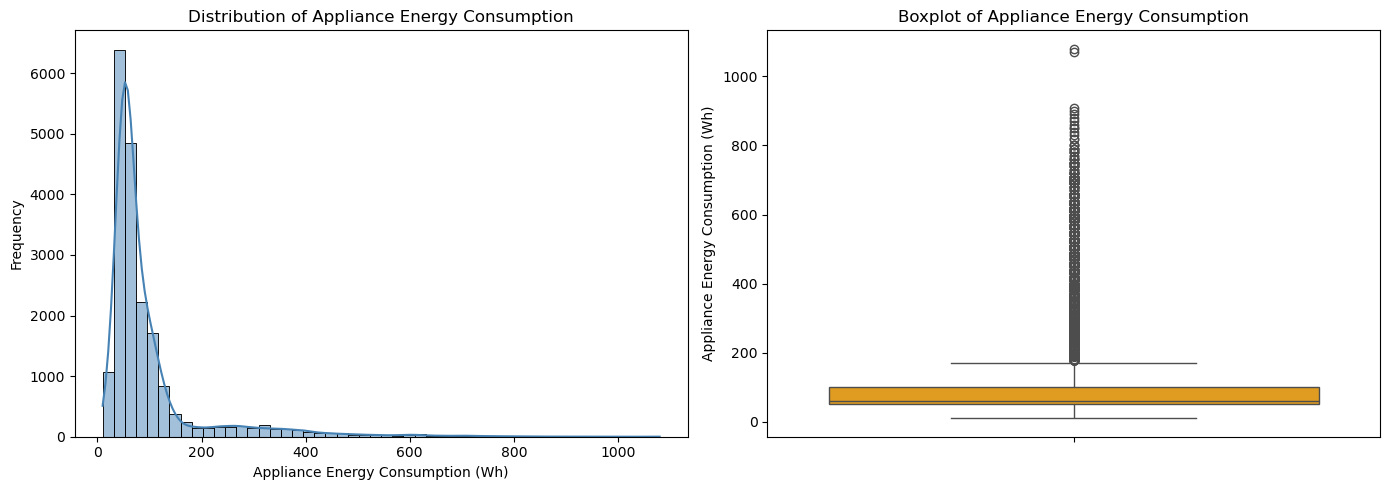

In [7]:
# Visualize appliance energy consumption distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["Appliances"],
    bins=50,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Appliance Energy Consumption")
axes[0].set_xlabel("Appliance Energy Consumption (Wh)")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    y=df["Appliances"],
    color="orange",
    ax=axes[1]
)

axes[1].set_title("Boxplot of Appliance Energy Consumption")
axes[1].set_ylabel("Appliance Energy Consumption (Wh)")

plt.tight_layout()

plt.savefig(
    "../figure/appliance_energy_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.3 Daily Appliance Energy Consumption Trends

This section examines how average appliance energy consumption changes over time.

Daily average consumption is calculated from the original 10-minute measurements to identify temporal patterns, fluctuations, and periods of unusually high or low demand.

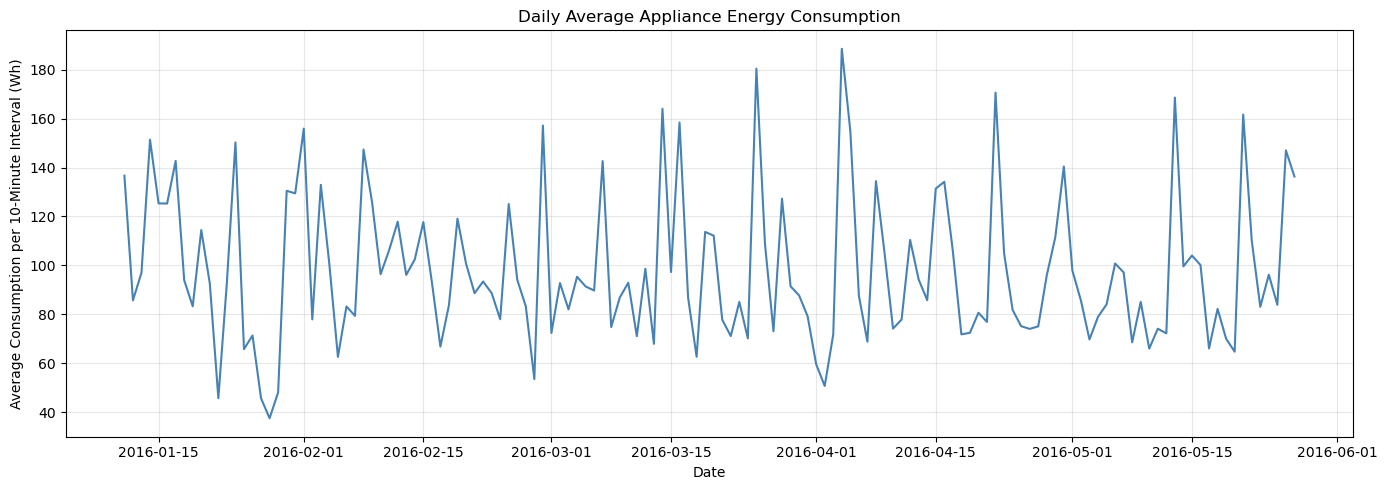

In [8]:
# Calculate daily average appliance energy consumption

daily_appliances = (
    df.set_index("date")["Appliances"]
    .resample("D")
    .mean()
)

# Plot daily average appliance consumption

plt.figure(figsize=(14, 5))

plt.plot(
    daily_appliances.index,
    daily_appliances.values,
    color="steelblue",
    linewidth=1.5
)

plt.title("Daily Average Appliance Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/daily_appliance_energy_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.4 Hourly Appliance Energy Consumption Profile

This section examines the average appliance energy consumption at each hour of the day.

The objective is to identify daily consumption patterns and determine whether appliance energy demand varies systematically across different hours.

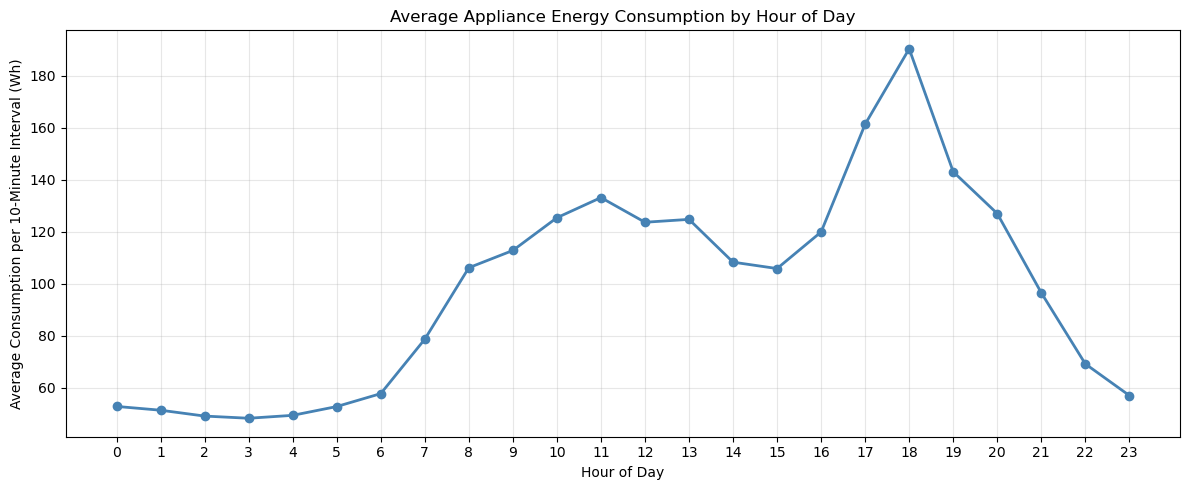

Highest consumption hour: 18
Lowest consumption hour: 3


In [9]:
# Calculate average appliance consumption by hour of day

hourly_profile = (
    df.groupby(df["date"].dt.hour)["Appliances"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Average Appliance Energy Consumption by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/hourly_appliance_energy_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Highest consumption hour:", hourly_profile.idxmax())
print("Lowest consumption hour:", hourly_profile.idxmin())

### 2.5 Correlation Analysis

Correlation analysis helps identify relationships between appliance energy consumption and environmental variables, including indoor temperature, humidity, and outdoor weather conditions.

Pearson correlation coefficients range from -1 to +1, where positive values indicate a positive linear relationship, negative values indicate a negative linear relationship, and values close to zero indicate a weak linear relationship.

In [10]:
# Section 2.5.1: Correlation with Appliance Energy Consumption

# Calculate Pearson correlation coefficients for numerical variables
correlation_matrix = df.select_dtypes(include="number").corr()

# Extract correlations with the target variable
appliance_correlations = (
    correlation_matrix["Appliances"]
    .drop("Appliances")
    .sort_values(ascending=False)
)

# Display correlation coefficients
display(appliance_correlations.to_frame(name="Correlation with Appliances").round(3))

,Correlation with Appliances
lights,0.197
T2,0.120
T6,0.118
T_out,0.099
Windspeed,0.087
RH_1,0.086
T3,0.085
T1,0.055
T4,0.040
T8,0.040


### 2.5.2 Visualization of Correlations with Appliance Energy Consumption

A horizontal bar chart is used to visualize the strength and direction of Pearson correlations between appliance energy consumption and the numerical predictor variables.

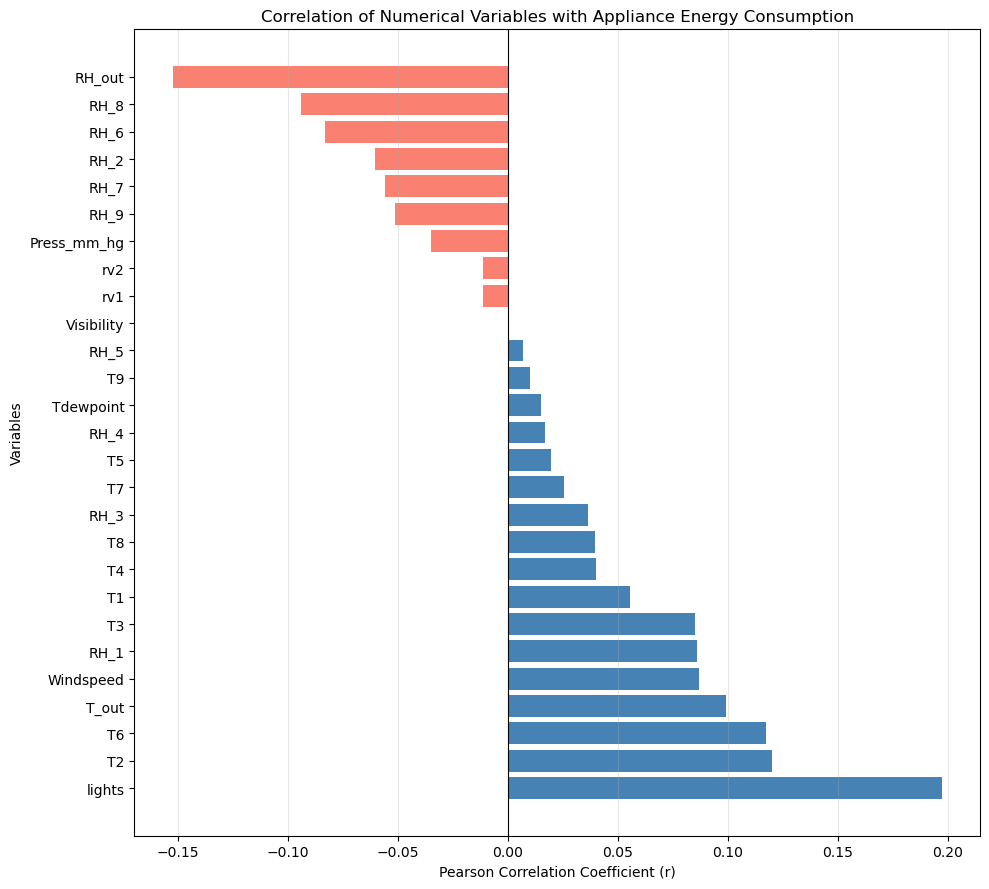

In [12]:
# Section 2.5.2: Correlation Visualization

plt.figure(figsize=(10, 9))

colors = [
    "steelblue" if value >= 0 else "salmon"
    for value in appliance_correlations.values
]

plt.barh(
    appliance_correlations.index,
    appliance_correlations.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Correlation of Numerical Variables with Appliance Energy Consumption")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.ylabel("Variables")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/appliance_correlation_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.5.3 Key Findings from Correlation Analysis

The correlation analysis revealed that most individual environmental and weather variables have weak linear relationships with appliance energy consumption.

Key observations include:

- Lighting consumption showed the strongest positive correlation with appliance energy consumption (r = 0.197).
- Outdoor relative humidity (RH_out) showed the strongest negative correlation (approximately r = -0.153).
- Indoor temperature measurements (T2 and T6) exhibited weak positive correlations.
- Most other variables showed correlations close to zero, indicating limited individual linear relationships with appliance consumption.

These findings suggest that appliance energy consumption may depend on a combination of environmental conditions, household activity patterns, and time-related factors.

Although individual correlations are weak, the variables may still contribute useful information to machine learning models through nonlinear relationships and interactions.

Correlation does not establish causation.

### 2.6 Weekday vs. Weekend Energy Consumption

This analysis examines whether household appliance energy consumption differs between weekdays and weekends.

Understanding these differences may help identify household activity patterns and support the development of time-based features for machine learning models.

In [13]:
# Section 2.6.1: Weekday vs. Weekend Energy Consumption

# Classify observations as Weekday or Weekend
df["Day_Type"] = np.where(
    df["date"].dt.dayofweek < 5,
    "Weekday",
    "Weekend"
)

# Calculate average appliance consumption by day type
day_type_consumption = (
    df.groupby("Day_Type")["Appliances"]
    .agg(["mean", "median", "std", "count"])
    .reindex(["Weekday", "Weekend"])
)

# Display summary statistics
display(day_type_consumption.round(2))

,mean,median,std,count
Day_Type,,,,
Weekday,96.59,60.0,103.09,14263
Weekend,100.58,70.0,101.00,5472


### 2.6.2 Visualization of Weekday vs. Weekend Energy Consumption

This visualization compares average appliance energy consumption during weekdays and weekends to identify potential differences associated with household activity patterns.

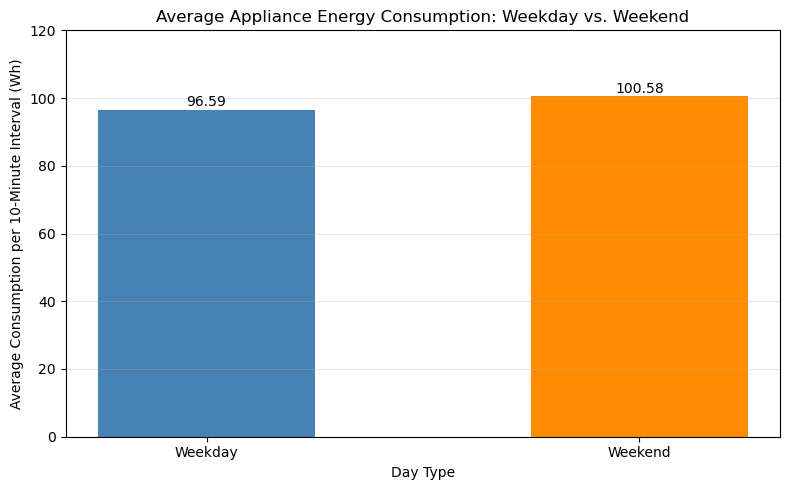

In [14]:
# Section 2.6.2: Weekday vs. Weekend Consumption Visualization

plt.figure(figsize=(8, 5))

bars = plt.bar(
    day_type_consumption.index,
    day_type_consumption["mean"],
    color=["steelblue", "darkorange"],
    width=0.5
)

# Add consumption values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}",
        ha="center"
    )

plt.title("Average Appliance Energy Consumption: Weekday vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.ylim(0, 120)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/weekday_weekend_energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.6.3 Key Findings: Weekday vs. Weekend Consumption

The analysis revealed a modest difference in appliance energy consumption between weekdays and weekends.

- Average weekday consumption was 96.59 Wh per 10-minute interval, compared with 100.58 Wh during weekends.
- Weekend consumption was approximately 4.1% higher than weekday consumption.
- Median consumption was also higher during weekends (70 Wh) than weekdays (60 Wh).
- Both groups exhibited substantial variability, suggesting that appliance consumption is influenced by factors beyond the day type alone.

These findings indicate that weekday/weekend classification may be useful as a time-based feature in subsequent machine learning models. However, further analysis is needed to determine its predictive importance.

### 2.7 High-Consumption Events and Outlier Analysis

This section investigates unusually high appliance energy consumption readings using the Interquartile Range (IQR) method.

The objective is to quantify the frequency of high-consumption events and assess their potential importance for subsequent predictive modeling.

In [15]:
# Section 2.7.1: Identifying High-Consumption Events

# Calculate the interquartile range
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the upper outlier threshold
upper_threshold = Q3 + 1.5 * IQR

# Identify unusually high consumption readings
high_consumption = df[df["Appliances"] > upper_threshold]

# Calculate their frequency
high_count = len(high_consumption)
high_percentage = (high_count / len(df)) * 100

# Display results
print(f"First Quartile (Q1): {Q1:.2f} Wh")
print(f"Third Quartile (Q3): {Q3:.2f} Wh")
print(f"Interquartile Range (IQR): {IQR:.2f} Wh")
print(f"Upper Outlier Threshold: {upper_threshold:.2f} Wh")
print(f"High-Consumption Observations: {high_count}")
print(f"Percentage of Observations: {high_percentage:.2f}%")

First Quartile (Q1): 50.00 Wh
Third Quartile (Q3): 100.00 Wh
Interquartile Range (IQR): 50.00 Wh
Upper Outlier Threshold: 175.00 Wh
High-Consumption Observations: 2138
Percentage of Observations: 10.83%


### 2.7.2 Key Findings from High-Consumption Event Analysis

The Interquartile Range (IQR) method identified 2,138 appliance energy consumption observations exceeding the upper threshold of 175 Wh per 10-minute interval. These observations represent approximately 10.83% of the dataset.

The relatively high proportion of observations above the threshold suggests that elevated appliance energy consumption occurs frequently enough to warrant attention during predictive modeling.

However, observations classified as outliers using the IQR method are not necessarily measurement errors. They may represent genuine household activities involving increased appliance usage.

**Decision:** High-consumption observations will be retained during exploratory analysis and initial model development. Their influence on predictive performance will be evaluated during model assessment.


### 2.8 Exploratory Data Analysis Summary

The exploratory data analysis provided important insights into household appliance energy consumption patterns and their relationships with environmental and time-related variables.

**Key Findings**

1. **Energy Consumption Distribution**
   - Appliance energy consumption is strongly right-skewed, with most observations concentrated at relatively low consumption levels.
   - Occasional high-consumption events contribute to substantial variability in energy usage.

2. **Daily and Hourly Consumption Patterns**
   - Daily average appliance consumption fluctuates considerably throughout the observation period.
   - Hourly analysis revealed the highest average consumption around 18:00 and the lowest around 03:00, suggesting that household activity schedules influence electricity demand.

3. **Correlation Analysis**
   - Lighting consumption exhibited the strongest positive linear correlation with appliance energy consumption (r = 0.197).
   - Outdoor relative humidity showed the strongest negative correlation (approximately r = -0.153).
   - Most environmental variables exhibited weak individual linear correlations, suggesting that nonlinear relationships and interactions may be important.

4. **Weekday vs. Weekend Consumption**
   - Average weekend appliance consumption was 100.58 Wh per 10-minute interval, compared with 96.59 Wh on weekdays.
   - The approximately 4.1% difference suggests that day type may provide useful information for prediction.

5. **High-Consumption Events**
   - The IQR method identified 2,138 observations (10.83%) exceeding 175 Wh per 10-minute interval.
   - These observations will be retained for initial modeling because they may represent genuine household energy usage.

**Implications for Predictive Modeling**

The findings indicate that appliance energy consumption may depend on a combination of environmental conditions, household activity patterns, and temporal characteristics.

The next phase will focus on feature engineering, including extracting useful time-related variables and preparing the dataset for machine learning.

Care will be taken to prevent data leakage and preserve the chronological structure of the observations during model development and evaluation.


## 3. Feature Engineering

Feature engineering transforms existing dataset variables into useful predictors for machine learning.

In this section, we will create time-based features, investigate potentially redundant variables, and prepare the dataset for predictive modeling while preserving its chronological structure.

### 3.1 Time-Based Feature Extraction

The timestamp column contains useful information about household energy consumption patterns. We will extract hour, day of week, month, and weekend indicators to help machine learning models identify temporal patterns.

In [16]:
# Section 3.1: Time-Based Feature Extraction

# Create a separate dataset for feature engineering
df_model = df.copy()

# Extract time-related features
df_model["hour"] = df_model["date"].dt.hour
df_model["day_of_week"] = df_model["date"].dt.dayofweek
df_model["month"] = df_model["date"].dt.month

# Weekend indicator: 1 = Weekend, 0 = Weekday
df_model["is_weekend"] = (
    df_model["day_of_week"] >= 5
).astype(int)

# Display the newly created features
display(
    df_model[
        ["date", "hour", "day_of_week", "month", "is_weekend"]
    ].head(10)
)

,date,hour,day_of_week,month,is_weekend
0,2016-01-11 17:00:00,17,0,1,0
1,2016-01-11 17:10:00,17,0,1,0
2,2016-01-11 17:20:00,17,0,1,0
3,2016-01-11 17:30:00,17,0,1,0
4,2016-01-11 17:40:00,17,0,1,0
5,2016-01-11 17:50:00,17,0,1,0
6,2016-01-11 18:00:00,18,0,1,0
7,2016-01-11 18:10:00,18,0,1,0
8,2016-01-11 18:20:00,18,0,1,0
9,2016-01-11 18:30:00,18,0,1,0


### 3.2 Cyclical Encoding of Time Features

Time-related variables such as hour of day and day of week follow repeating cycles.

To represent these patterns appropriately, sine and cosine transformations are applied to the hour and day-of-week features.

This encoding preserves the cyclical relationship between time values and may improve the ability of machine learning models to identify recurring energy consumption patterns.

In [17]:
# Section 3.2: Cyclical Encoding of Time Features

# Encode hour of day (24-hour cycle)
df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["hour"] / 24
)

# Encode day of week (7-day cycle)
df_model["day_sin"] = np.sin(
    2 * np.pi * df_model["day_of_week"] / 7
)

df_model["day_cos"] = np.cos(
    2 * np.pi * df_model["day_of_week"] / 7
)

# Display the new cyclical features
display(
    df_model[
        ["hour", "hour_sin", "hour_cos",
         "day_of_week", "day_sin", "day_cos"]
    ].head(10).round(3)
)

,hour,hour_sin,hour_cos,day_of_week,day_sin,day_cos
0,17,-0.966,-0.259,0,0.0,1.0
1,17,-0.966,-0.259,0,0.0,1.0
2,17,-0.966,-0.259,0,0.0,1.0
3,17,-0.966,-0.259,0,0.0,1.0
4,17,-0.966,-0.259,0,0.0,1.0
5,17,-0.966,-0.259,0,0.0,1.0
6,18,-1.000,-0.000,0,0.0,1.0
7,18,-1.000,-0.000,0,0.0,1.0
8,18,-1.000,-0.000,0,0.0,1.0
9,18,-1.000,-0.000,0,0.0,1.0



### 3.3 Lag Features for Appliance Energy Consumption

Lag features represent historical appliance energy consumption values at earlier time intervals.

Since the dataset contains measurements recorded every 10 minutes, lag features are created for 10-minute, 30-minute, and 60-minute intervals.

These features allow machine learning models to capture short-term dependencies in household energy consumption.

Only past observations are used to avoid introducing future information into the prediction process.


In [18]:

# Section 3.3: Creating Lag Features

# Previous 10-minute consumption
df_model["Appliances_lag_1"] = df_model["Appliances"].shift(1)

# Previous 30-minute consumption
df_model["Appliances_lag_3"] = df_model["Appliances"].shift(3)

# Previous 60-minute consumption
df_model["Appliances_lag_6"] = df_model["Appliances"].shift(6)

# Display original consumption and lag features
display(
    df_model[
        ["date", "Appliances",
         "Appliances_lag_1",
         "Appliances_lag_3",
         "Appliances_lag_6"]
    ].head(10)
)


,date,Appliances,Appliances_lag_1,Appliances_lag_3,Appliances_lag_6
0,2016-01-11 17:00:00,60,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,60.0,NaN,NaN
2,2016-01-11 17:20:00,50,60.0,NaN,NaN
3,2016-01-11 17:30:00,50,50.0,60.0,NaN
4,2016-01-11 17:40:00,60,50.0,60.0,NaN
5,2016-01-11 17:50:00,50,60.0,50.0,NaN
6,2016-01-11 18:00:00,60,50.0,50.0,60.0
7,2016-01-11 18:10:00,60,60.0,60.0,60.0
8,2016-01-11 18:20:00,60,60.0,50.0,50.0
9,2016-01-11 18:30:00,70,60.0,60.0,50.0



### 3.4 Rolling Average Features

Rolling average features summarize recent appliance energy consumption over specified time windows.

Two rolling averages are created:

- **30-minute rolling average:** Average consumption over the previous three observations.
- **60-minute rolling average:** Average consumption over the previous six observations.

These features help machine learning models capture short-term consumption trends and reduce sensitivity to individual fluctuations.

The calculations use only historical observations to prevent target leakage.


In [19]:

# Section 3.4: Creating Rolling Average Features

# Shift consumption by one interval to exclude the current target value
past_consumption = df_model["Appliances"].shift(1)

# Average of the previous 3 observations (30 minutes)
df_model["Appliances_rolling_mean_3"] = (
    past_consumption.rolling(window=3).mean()
)

# Average of the previous 6 observations (60 minutes)
df_model["Appliances_rolling_mean_6"] = (
    past_consumption.rolling(window=6).mean()
)

# Display original consumption and rolling features
display(
    df_model[
        ["date", "Appliances",
         "Appliances_rolling_mean_3",
         "Appliances_rolling_mean_6"]
    ].head(12).round(2)
)


,date,Appliances,Appliances_rolling_mean_3,Appliances_rolling_mean_6
0,2016-01-11 17:00:00,60,NaN,NaN
1,2016-01-11 17:10:00,60,NaN,NaN
2,2016-01-11 17:20:00,50,NaN,NaN
3,2016-01-11 17:30:00,50,56.67,NaN
4,2016-01-11 17:40:00,60,53.33,NaN
5,2016-01-11 17:50:00,50,53.33,NaN
6,2016-01-11 18:00:00,60,53.33,55.00
7,2016-01-11 18:10:00,60,56.67,55.00
8,2016-01-11 18:20:00,60,56.67,55.00
9,2016-01-11 18:30:00,70,60.00,56.67



### 3.5 Identifying Redundant Features

The original dataset contains two random variables, `rv1` and `rv2`, which exhibited identical descriptive statistics during exploratory data analysis.

This section verifies whether these variables contain identical values.

Redundant or uninformative features may introduce unnecessary complexity into machine learning models. Therefore, their relevance will be considered before constructing the final modeling dataset.


In [20]:

# Section 3.5: Identifying Redundant Features

# Check whether rv1 and rv2 contain identical values
identical_random_variables = df_model["rv1"].equals(df_model["rv2"])

# Calculate their correlation
random_variable_correlation = df_model["rv1"].corr(df_model["rv2"])

print("Are rv1 and rv2 identical?", identical_random_variables)
print(f"Correlation between rv1 and rv2: {random_variable_correlation:.4f}")


Are rv1 and rv2 identical? True
Correlation between rv1 and rv2: 1.0000



### 3.6 Preparing the Modeling Dataset

The engineered dataset is prepared for machine learning by removing redundant variables and handling missing values introduced by lag and rolling-average calculations.

The random variables `rv1` and `rv2` are excluded because they do not represent meaningful household energy characteristics.

The first six observations are expected to contain missing values because historical consumption measurements are unavailable for those timestamps.

The remaining observations will be preserved in chronological order for subsequent model development.


In [21]:

# Section 3.6.1: Preparing the Modeling Dataset

# Remove random variables
df_model = df_model.drop(columns=["rv1", "rv2"])

# Record the original number of observations
rows_before = len(df_model)

# Remove rows with missing values introduced by lag/rolling features
df_model = df_model.dropna().reset_index(drop=True)

# Verify dataset preparation
print("Observations before cleaning:", rows_before)
print("Observations after cleaning:", len(df_model))
print("Observations removed:", rows_before - len(df_model))
print("Remaining missing values:", df_model.isnull().sum().sum())
print("Number of columns:", df_model.shape[1])
print("Chronological order preserved:", df_model["date"].is_monotonic_increasing)


Observations before cleaning: 19735
Observations after cleaning: 19729
Observations removed: 6
Remaining missing values: 0
Number of columns: 41
Chronological order preserved: True



### 3.6.2 Separating Predictors and Target Variable

The target variable for this project is `Appliances`, representing appliance energy consumption in Wh per 10-minute interval.

The predictor matrix contains the available environmental measurements and engineered time-series features.

The raw timestamp and categorical day-type label are excluded because numerical time-related features have already been created.

The resulting feature matrix and target vector will be used for chronological model training and evaluation.


In [22]:

# Section 3.6.2: Separating Predictors and Target Variable

# Define the target variable
y = df_model["Appliances"]

# Define predictors
X = df_model.drop(
    columns=["Appliances", "date", "Day_Type"]
)

# Verify feature and target dimensions
print("Predictor matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Number of predictor features:", X.shape[1])
print("Target variable:", y.name)

# Check for missing values
print("Missing values in predictors:", X.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())


Predictor matrix shape: (19729, 38)
Target vector shape: (19729,)
Number of predictor features: 38
Target variable: Appliances
Missing values in predictors: 0
Missing values in target: 0



### 3.7 Chronological Train/Test Split

The dataset is divided into training (80%) and testing (20%) sets using chronological order.

The earliest 80% of observations are used for model training, while the most recent 20% are reserved for evaluating predictive performance.

Random shuffling is avoided because it could introduce future observations into the training data and produce overly optimistic evaluation results.

This approach better reflects real-world time-series prediction, where models learn from historical data to predict future energy consumption.


In [23]:

# Section 3.7: Chronological Train/Test Split

# Determine the split point
split_index = int(len(X) * 0.8)

# Split predictors chronologically
X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

# Split target chronologically
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Display dataset sizes
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training percentage:", round(len(X_train) / len(X) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X) * 100, 2))

# Verify chronological boundaries
print("\nTraining period:")
print(df_model["date"].iloc[0], "to", df_model["date"].iloc[split_index - 1])

print("\nTesting period:")
print(df_model["date"].iloc[split_index], "to", df_model["date"].iloc[-1])


Training observations: 15783
Testing observations: 3946
Training percentage: 80.0
Testing percentage: 20.0

Training period:
2016-01-11 18:00:00 to 2016-04-30 08:20:00

Testing period:
2016-04-30 08:30:00 to 2016-05-27 18:00:00


### 3.8 Preparing the 10-Minute-Ahead Forecasting Dataset

The objective is to predict appliance energy consumption 10 minutes into the future using information available at the current timestamp. The forecasting target is created by shifting appliance consumption one observation forward, while preserving chronological order.

In [24]:
# Section 3.8.1: Create the 10-minute-ahead forecasting target

# Create a copy to preserve the existing modeling dataset
df_forecast = df_model.copy()

# Target: appliance consumption at the next 10-minute interval
df_forecast["Appliances_next_10min"] = (
    df_forecast["Appliances"].shift(-1)
)

# Display the current and future consumption values
display(
    df_forecast[
        ["date", "Appliances", "Appliances_next_10min"]
    ].head(10)
)

,date,Appliances,Appliances_next_10min
0,2016-01-11 18:00:00,60,60.0
1,2016-01-11 18:10:00,60,60.0
2,2016-01-11 18:20:00,60,70.0
3,2016-01-11 18:30:00,70,230.0
4,2016-01-11 18:40:00,230,580.0
5,2016-01-11 18:50:00,580,430.0
6,2016-01-11 19:00:00,430,250.0
7,2016-01-11 19:10:00,250,100.0
8,2016-01-11 19:20:00,100,100.0
9,2016-01-11 19:30:00,100,90.0


In [25]:
# Section 3.8.2: Remove rows without a future target

rows_before = len(df_forecast)

# Remove the final observation without a future target
df_forecast = df_forecast.dropna(
    subset=["Appliances_next_10min"]
).reset_index(drop=True)

# Verify the forecasting dataset
print("Observations before:", rows_before)
print("Observations after:", len(df_forecast))
print("Observations removed:", rows_before - len(df_forecast))
print("Missing target values:", df_forecast["Appliances_next_10min"].isna().sum())

# Verify that each target corresponds to exactly 10 minutes ahead
print(
    "All forecast intervals are 10 minutes:",
    (
        df_forecast["date"].shift(-1).iloc[:-1]
        - df_forecast["date"].iloc[:-1]
    ).eq(pd.Timedelta(minutes=10)).all()
)

Observations before: 19729
Observations after: 19728
Observations removed: 1
Missing target values: 0
All forecast intervals are 10 minutes: True


In [26]:
# Section 3.8.3: Define forecasting predictors and target

# Define the future consumption target
y_forecast = df_forecast["Appliances_next_10min"]

# Exclude the future target and non-predictor columns
X_forecast = df_forecast.drop(
    columns=[
        "Appliances_next_10min",
        "date",
        "Day_Type",
        "rv1",
        "rv2"
    ],
    errors="ignore"
)

# Verify the forecasting dataset
print("Forecasting predictor matrix:", X_forecast.shape)
print("Forecasting target vector:", y_forecast.shape)
print("Number of forecasting features:", X_forecast.shape[1])
print("Missing predictor values:", X_forecast.isnull().sum().sum())
print("Missing target values:", y_forecast.isnull().sum())

Forecasting predictor matrix: (19728, 39)
Forecasting target vector: (19728,)
Number of forecasting features: 39
Missing predictor values: 0
Missing target values: 0


In [27]:
# Section 3.8.4: Chronological forecasting train/test split

# Define the split point
forecast_split_index = int(len(X_forecast) * 0.8)

# Split predictors chronologically
X_train_forecast = X_forecast.iloc[:forecast_split_index].copy()
X_test_forecast = X_forecast.iloc[forecast_split_index:].copy()

# Split the forecasting target
y_train_forecast = y_forecast.iloc[:forecast_split_index].copy()
y_test_forecast = y_forecast.iloc[forecast_split_index:].copy()

# Verify the split
print("Training observations:", len(X_train_forecast))
print("Testing observations:", len(X_test_forecast))

print("Training percentage:", round(len(X_train_forecast) / len(X_forecast) * 100, 2))
print("Testing percentage:", round(len(X_test_forecast) / len(X_forecast) * 100, 2))

print("\nTraining period:")
print(
    df_forecast["date"].iloc[0],
    "to",
    df_forecast["date"].iloc[forecast_split_index - 1]
)

print("\nTesting period:")
print(
    df_forecast["date"].iloc[forecast_split_index],
    "to",
    df_forecast["date"].iloc[-1]
)

Training observations: 15782
Testing observations: 3946
Training percentage: 80.0
Testing percentage: 20.0

Training period:
2016-01-11 18:00:00 to 2016-04-30 08:10:00

Testing period:
2016-04-30 08:20:00 to 2016-05-27 17:50:00


In [28]:
# Section 3.8.5: Verify forecasting boundaries

train_last_input = df_forecast["date"].iloc[forecast_split_index - 1]
test_first_input = df_forecast["date"].iloc[forecast_split_index]

train_last_target = train_last_input + pd.Timedelta(minutes=10)
test_first_target = test_first_input + pd.Timedelta(minutes=10)

print("Last training input:", train_last_input)
print("Last training target:", train_last_target)

print("\nFirst testing input:", test_first_input)
print("First testing target:", test_first_target)

print("\nTraining targets precede testing targets:",
      train_last_target < test_first_target)

print("Training and testing input rows overlap:",
      not X_train_forecast.index.intersection(X_test_forecast.index).empty)

Last training input: 2016-04-30 08:10:00
Last training target: 2016-04-30 08:20:00

First testing input: 2016-04-30 08:20:00
First testing target: 2016-04-30 08:30:00

Training targets precede testing targets: True
Training and testing input rows overlap: False


In [29]:
# Section 3.8.6: Inspect forecasting predictor features

# Display all predictor columns
print("Forecasting predictor features:")
for i, column in enumerate(X_forecast.columns, start=1):
    print(f"{i}. {column}")

# Check whether the future target is included among predictors
print("\nFuture target included in predictors:",
      "Appliances_next_10min" in X_forecast.columns)

# Check whether the current appliance consumption is available
print("Current appliance consumption included:",
      "Appliances" in X_forecast.columns)

Forecasting predictor features:
1. Appliances
2. lights
3. T1
4. RH_1
5. T2
6. RH_2
7. T3
8. RH_3
9. T4
10. RH_4
11. T5
12. RH_5
13. T6
14. RH_6
15. T7
16. RH_7
17. T8
18. RH_8
19. T9
20. RH_9
21. T_out
22. Press_mm_hg
23. RH_out
24. Windspeed
25. Visibility
26. Tdewpoint
27. hour
28. day_of_week
29. month
30. is_weekend
31. hour_sin
32. hour_cos
33. day_sin
34. day_cos
35. Appliances_lag_1
36. Appliances_lag_3
37. Appliances_lag_6
38. Appliances_rolling_mean_3
39. Appliances_rolling_mean_6

Future target included in predictors: False
Current appliance consumption included: True


# Section 4: Forecasting Model Development and Evaluation

## 4.1 Persistence Baseline Model

The persistence model predicts that appliance energy consumption in the next 10-minute interval will remain equal to the current consumption. It provides a simple benchmark for evaluating the performance of more advanced forecasting models.

In [30]:
# Section 4.1: Persistence Baseline Model

# Predict next-interval consumption using current consumption
y_pred_persistence = X_test_forecast["Appliances"].copy()

# Display actual and predicted consumption
persistence_results = pd.DataFrame({
    "Actual_Consumption": y_test_forecast.values,
    "Predicted_Consumption": y_pred_persistence.values
})

display(persistence_results.head(10))

,Actual_Consumption,Predicted_Consumption
0,590.0,370
1,320.0,590
2,310.0,320
3,260.0,310
4,190.0,260
5,150.0,190
6,130.0,150
7,290.0,130
8,490.0,290
9,840.0,490


## 4.2 Persistence Baseline Model Evaluation

The persistence baseline is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²). These metrics will serve as benchmarks for comparing subsequent machine learning forecasting models.

In [31]:
# Section 4.2: Evaluate Persistence Baseline Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
persistence_mae = mean_absolute_error(y_test_forecast, y_pred_persistence)

persistence_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, y_pred_persistence)
)

persistence_r2 = r2_score(y_test_forecast, y_pred_persistence)

# Display results
print("Persistence Baseline Model Performance")
print(f"MAE:  {persistence_mae:.2f} Wh")
print(f"RMSE: {persistence_rmse:.2f} Wh")
print(f"R²:   {persistence_r2:.4f}")

Persistence Baseline Model Performance
MAE:  26.64 Wh
RMSE: 66.44 Wh
R²:   0.4664
